# UCS420 Assignment 7 — NLP-I
**Name:** Nikunj  
**Roll number:** 1024160098

The dataset below is produced by the official generator for this roll number. `generate_dataset()` and `process_ticket()` are unchanged.

In [1]:
ROLL_NO = 1024160098
NAME = "Nikunj"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"
print("Roll number:", ROLL_NO)
print("Name:", NAME)

Roll number: 1024160098
Name: Nikunj


### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}")
print("Focus tickets:", FOCUS)
print()
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160098   Name: Nikunj   Fingerprint: 8D4A48A7   Tickets: 15
Focus tickets: ['T01', 'T11']

Ticket_ID                                                                                         Ticket_Text
      T01                        Wi-Fi has stopped syncing when connected to campus Wi-Fi. Please resolve it.
      T02                         I couldn't connect to the printer after resetting my password. Please help.
      T03                    Python was working yesterday before the assignment deadline. Can you check this?
      T04          I couldn't connect to the password while uploading the file. It works on another computer.
      T05                                      The printer keeps asking for login. Is there another solution?
      T06                                                           The printer won't print; it isn't jammed.
      T07                       I was locked out of the projector during the lab. I have tried several times!
      T08   

---
## Q1. Preprocessing
Run `process_ticket()` on every ticket. The table reports, for each ticket, the number of sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens. The TOTAL row is the sum of these counts. Unique tokens are the distinct strings in that ticket's token list. Ticket T01 (one of the generator's focus tickets) is then printed with the actual token lists.

In [5]:
rows = []
processed = {}
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    processed[row["Ticket_ID"]] = result
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "sentences": len(result["sentences"]),
        "tokens": len(result["tokens"]),
        "punctuation": len(result["punct"]),
        "stopwords": len(result["stops"]),
        "unique_tokens": len(set(result["tokens"])),
        "final_tokens": len(result["final"]),
    })

table = pd.DataFrame(rows)
total = {"Ticket_ID": "TOTAL"}
for col in ["sentences", "tokens", "punctuation", "stopwords", "unique_tokens", "final_tokens"]:
    total[col] = int(table[col].sum())
table = pd.concat([table, pd.DataFrame([total])], ignore_index=True)
print(table.to_string(index=False))

selected = "T01"
print("\nSelected ticket:", selected)
print(df.loc[df["Ticket_ID"] == selected, "Ticket_Text"].iloc[0])
shown = processed[selected]
print("tokens:           ", shown["tokens"])
print("punctuation:      ", shown["punct"])
print("stopwords:        ", shown["stops"])
print("final tokens:     ", shown["final"])

non_words = sorted({
    tok for result in processed.values() for tok in result["final"]
    if (not tok.replace("-", "").isalpha()) or tok in {"n't", "wo", "ca"}
})
print("\nFinal tokens that are not ordinary words:", non_words)
print(
    "n't and wo are left behind when word_tokenize splits contractions: "
    "isn't/didn't/couldn't -> ... + n't, and won't -> wo + n't. "
    "The stems is/could/did are stopwords, so only n't and wo survive in the final list. "
    "university.edu is the domain left after word_tokenize splits the email at @. "
    "95.5 is a percentage kept as one numeric token."
)

Ticket_ID  sentences  tokens  punctuation  stopwords  unique_tokens  final_tokens
      T01          2      14            2          4             12             8
      T02          2      15            2          5             14             8
      T03          2      14            2          6             14             6
      T04          2      18            2          7             16             9
      T05          2      12            2          4             12             6
      T06          1      11            2          3             10             6
      T07          2      17            2          9             15             6
      T08          2      15            2          5             14             8
      T09          2      16            2          6             14             8
      T10          2      10            4          2              9             4
      T11          2      17            2          9             16             6
      T12       

---
## Q2. Regex extraction and replacement
`re.findall` extracts words longer than 5 letters, numbers (decimals, versions and thousands-separators stay whole), capitalized words, and words that begin with a vowel. `re.sub` replaces emails, URLs and phone numbers. The same patterns are checked on `TEST_LINES` and then applied to the tickets.

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

LONG_WORD = r"\b[A-Za-z]{6,}(?:'[A-Za-z]+)?\b"
NUMBER = r"\b(?:0x[0-9A-Fa-f]+|\d+(?:[.,]\d+)*)\b"
CAPITAL = r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b"
VOWEL = r"\b[AEIOUaeiou][A-Za-z']*\b"
EMAIL = r"[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}"
URL = r"https?://[A-Za-z0-9./_\-]+|www\.[A-Za-z0-9./_\-]+"
PHONE = r"\+91[\s\-]?\d{5}[\s\-]?\d{5}|\b\d{4}-\d{3}-\d{4}\b"

def redact(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

print("=== TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {i}: {line}")
    print("  words > 5 letters:", re.findall(LONG_WORD, line))
    print("  numbers:          ", re.findall(NUMBER, line))
    print("  capitalized:      ", re.findall(CAPITAL, line))
    print("  starts with vowel:", re.findall(VOWEL, line))
    print("  redacted:         ", redact(line))

corpus = "\n".join(df["Ticket_Text"])
print("\n=== TICKETS ===")
print("words > 5 letters:", re.findall(LONG_WORD, corpus))
print("numbers:          ", re.findall(NUMBER, corpus))
print("capitalized:      ", re.findall(CAPITAL, corpus))
print("starts with vowel:", re.findall(VOWEL, corpus))
print("\nRedacted tickets:")
for _, row in df.iterrows():
    cleaned = redact(row["Ticket_Text"])
    if cleaned != row["Ticket_Text"]:
        print(f"  {row['Ticket_ID']}: {cleaned}")

sentence_initial = []
content_caps = []
for _, row in df.iterrows():
    for match in re.finditer(CAPITAL, row["Ticket_Text"]):
        prefix = row["Ticket_Text"][:match.start()]
        if prefix.strip() == "" or prefix.rstrip().endswith((".", "!", "?")):
            sentence_initial.append(match.group())
        else:
            content_caps.append(match.group())
print(f"\nCapitalized words: {len(sentence_initial) + len(content_caps)}")
print(f"Capitalized only because they start a sentence: {len(sentence_initial)}")
print("Those words:", sentence_initial)
print(f"Capitalized inside the sentence: {len(content_caps)} -> {content_caps}")
print(
    "27 of the 31 capitalized matches sit at the start of a sentence. "
    "The other 4 are mid-sentence: Wi-Fi twice (the network name), MATLAB and ASAP. "
    "T01 also begins with Wi-Fi, so that one match is a proper name that happens to start the ticket."
)

=== TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
  numbers:           []
  capitalized:       ['Mail']
  starts with vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  redacted:          Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  words > 5 letters: ['Version']
  numbers:           ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  capitalized:       ['Call', 'Version', 'Rs']
  starts with vowel: ['or', 'is']
  redacted:          Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  words > 5 letters: []
  numbers:           ['5.30']
  capitalized

---
## Q3. Custom tokenization
`my_tokenize` uses one `RegexpTokenizer` pattern. More specific alternatives come first so emails, URLs, phone numbers, versions, decimals, hyphenated words and contractions are kept as single tokens.

In [7]:
from nltk.tokenize import RegexpTokenizer

TOKEN_PATTERN = r"""(?x)
    (?:https?://|www\.)[A-Za-z0-9\-]+(?:\.[A-Za-z0-9\-]+)+(?:/[A-Za-z0-9_\-]+)*
  | [A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}
  | \+91(?:[\s\-]\d{5}){2}
  | \b\d{4}-\d{3}-\d{4}\b
  | \d+(?:\.\d+)+
  | \d{1,3}(?:,\d{3})+
  | [A-Za-z]+(?:-[A-Za-z]+)+
  | [A-Za-z]+(?:'[A-Za-z]+)?
  | \d+
  | [^\w\s]
"""
tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("=== TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    mine = my_tokenize(line)
    official = word_tokenize(line)
    print(f"\nLine {i}: {line}")
    print("  my_tokenize:  ", mine)
    print("  word_tokenize:", official)

print("\n=== TICKETS ===")
different = []
for _, row in df.iterrows():
    mine = my_tokenize(row["Ticket_Text"])
    official = word_tokenize(row["Ticket_Text"])
    if mine != official:
        different.append(row["Ticket_ID"])
        print(f"\n{row['Ticket_ID']}: {row['Ticket_Text']}")
        print("  my_tokenize:  ", mine)
        print("  word_tokenize:", official)

print(f"\nTickets tokenized differently: {len(different)} of {len(df)} -> {different}")
print(
    "Three differences:\n"
    "1. Contractions stay whole in my_tokenize (couldn't, won't, isn't) but word_tokenize "
    "splits them into could/wo/is and n't.\n"
    "2. Emails stay whole (helpdesk@university.edu). word_tokenize splits them at @.\n"
    "3. word_tokenize also splits 'cannot' into 'can' and 'not'. my_tokenize keeps cannot "
    "as one token, so the negation is not lost.\n"
    "On TEST_LINES the same pattern also keeps URLs, spaced phone numbers (+91 98765 43210), "
    "versions (2.0.1), decimals (95.5, 5.30) and hyphenated words (state-of-the-art) together. "
    "word_tokenize breaks the URL at ':' and '//' and splits the spaced phone number."
)

=== TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-the-art lab isn't open; log-in

---
## Q4. Stemming and lemmatization
Compared on the unique final tokens: Porter, Lancaster, a Regexp stemmer, and WordNet lemmatization with POS tags. The Regexp suffix is `ing$`, chosen because this dataset contains uploading, syncing, working, opening, asking and resetting. The minimum length is 5 so a short word is not stripped. The table keeps only words whose four outputs are not identical. POS is the most frequent `nltk.pos_tag` label of that final token in the tickets.

In [8]:
from collections import Counter
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

pos_counts = {}
for _, row in df.iterrows():
    for word, tag in nltk.pos_tag(word_tokenize(row["Ticket_Text"])):
        lowered = word.lower()
        if is_punct(lowered) or lowered in STOP:
            continue
        pos_counts.setdefault(lowered, Counter())[tag] += 1

unique_final = sorted({tok for result in processed.values() for tok in result["final"]})
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$", min=5)
lemmatizer = WordNetLemmatizer()

compared = []
for word in unique_final:
    tag = pos_counts.get(word, Counter({"NN": 1})).most_common(1)[0][0]
    outputs = {
        "porter": porter.stem(word),
        "lancaster": lancaster.stem(word),
        "regexp_ing": regexp_stemmer.stem(word),
        "lemma": lemmatizer.lemmatize(word, wordnet_pos(tag)),
    }
    if len(set(outputs.values())) > 1:
        compared.append({"word": word, "pos": tag, **outputs})

diff_table = pd.DataFrame(compared)
print("Regexp suffix: ing$   min length: 5")
print("Words that end in -ing in this dataset:",
      [w for w in unique_final if w.endswith("ing")])
print(f"\nWords where the four methods disagree: {len(diff_table)} of {len(unique_final)}\n")
print(diff_table.to_string(index=False))
print(
    "\nOver-stemming: Lancaster reduces 'opening' and 'open' to 'op', and 'syncing' to 'synt'. "
    "The stem is shorter than the real root and collides with unrelated words.\n"
    "Under-stemming: RegexpStemmer('ing$') turns 'resetting' into 'resett'. "
    "The -ing suffix is gone, but the doubled consonant is still there, so it does not reach 'reset'. "
    "The same stemmer also leaves 'stopped' and 'uploaded' untouched because those use -ed, not -ing."
)

Regexp suffix: ing$   min length: 5
Words that end in -ing in this dataset: ['asking', 'opening', 'resetting', 'syncing', 'uploading', 'working']

Words where the four methods disagree: 35 of 59

      word pos    porter lancaster regexp_ing      lemma
   another  DT     anoth     anoth    another    another
assignment  JJ    assign    assign assignment assignment
    campus  VB     campu      camp     campus     campus
  computer  NN    comput    comput   computer   computer
 connected VBN   connect   connect  connected    connect
   crashes NNS     crash     crash    crashes      crash
  deadline  NN   deadlin   deadlin   deadline   deadline
    failed VBD      fail      fail     failed       fail
      file  NN      file       fil       file       file
     fixed VBN       fix       fix      fixed        fix
    jammed VBN       jam       jam     jammed        jam
     keeps VBZ      keep      keep      keeps       keep
    locked VBN      lock      lock     locked       lock
    oc

---
## Q5. Corpus statistics
S1 is every token. S2 drops punctuation. S3 is the final token list (no punctuation, no stopwords). S4 is S3 after the Porter stemmer. TTR is unique types divided by total tokens.

              set  total  unique    TTR
    S1 all tokens    200      94 0.4700
S2 no punctuation    168      86 0.5119
  S3 final tokens     94      59 0.6277
    S4 Porter(S3)     94      55 0.5851

Top 10 words in S1:
  '.'                  20
  'the'                15
  'i'                  6
  'to'                 5
  'it'                 5
  '?'                  5
  "n't"                4
  'is'                 4
  'wi-fi'              3
  'has'                3

Top 10 words in S3:
  "n't"                4
  'wi-fi'              3
  'stopped'            3
  'syncing'            3
  'printer'            3
  'assignment'         3
  'deadline'           3
  'another'            3
  'connected'          2
  'campus'             2

Top 5 bigrams in S1:
  ('.', 'i')  4
  ('.', 'the')  4
  ('has', 'stopped')  3
  ('stopped', 'syncing')  3
  ('the', 'printer')  3

Top 5 bigrams in S3:
  ('stopped', 'syncing')  3
  ('assignment', 'deadline')  3
  ('connected', 'campus')  2
  ('campus', 

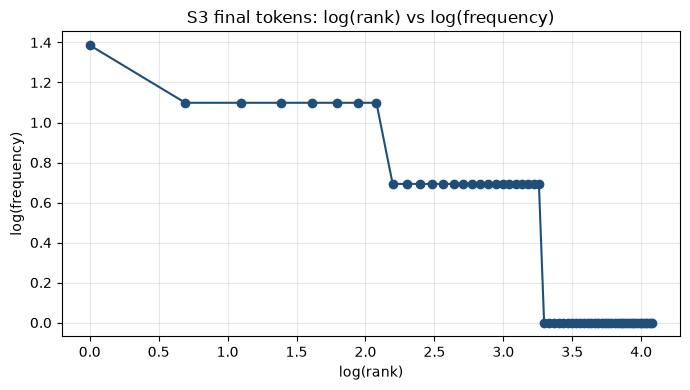

TTR rises from S1 to S3 and then falls at S4. S1 is padded with a few repeated stopwords and periods ('.' , 'the', 'to'), so many tokens add almost no new types and TTR stays low. Removing punctuation (S2) and then stopwords (S3) deletes those high-frequency repeats, so the remaining content words are more varied and TTR goes up. Porter stemming (S4) keeps the same number of tokens but merges variants such as working/works and uploading/uploaded, which cuts the number of unique types, so TTR falls.


In [9]:
%matplotlib inline
import math
from nltk import bigrams
import matplotlib.pyplot as plt

s1 = [tok for result in processed.values() for tok in result["tokens"]]
s2 = [tok for result in processed.values() for tok in result["tokens"] if not is_punct(tok)]
s3 = [tok for result in processed.values() for tok in result["final"]]
s4 = [porter.stem(tok) for tok in s3]

def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0.0

stats = pd.DataFrame([
    {"set": "S1 all tokens", "total": len(s1), "unique": len(set(s1)), "TTR": round(ttr(s1), 4)},
    {"set": "S2 no punctuation", "total": len(s2), "unique": len(set(s2)), "TTR": round(ttr(s2), 4)},
    {"set": "S3 final tokens", "total": len(s3), "unique": len(set(s3)), "TTR": round(ttr(s3), 4)},
    {"set": "S4 Porter(S3)", "total": len(s4), "unique": len(set(s4)), "TTR": round(ttr(s4), 4)},
])
print(stats.to_string(index=False))

print("\nTop 10 words in S1:")
for word, count in Counter(s1).most_common(10):
    print(f"  {word!r:20} {count}")
print("\nTop 10 words in S3:")
for word, count in Counter(s3).most_common(10):
    print(f"  {word!r:20} {count}")

print("\nTop 5 bigrams in S1:")
for gram, count in Counter(bigrams(s1)).most_common(5):
    print(f"  {gram}  {count}")
print("\nTop 5 bigrams in S3:")
for gram, count in Counter(bigrams(s3)).most_common(5):
    print(f"  {gram}  {count}")

frequencies = sorted(Counter(s3).values(), reverse=True)
log_rank = [math.log(rank) for rank in range(1, len(frequencies) + 1)]
log_freq = [math.log(freq) for freq in frequencies]
plt.figure(figsize=(7, 4))
plt.plot(log_rank, log_freq, marker="o", color="#1f4e79")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 final tokens: log(rank) vs log(frequency)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "TTR rises from S1 to S3 and then falls at S4. "
    "S1 is padded with a few repeated stopwords and periods ('.' , 'the', 'to'), "
    "so many tokens add almost no new types and TTR stays low. "
    "Removing punctuation (S2) and then stopwords (S3) deletes those high-frequency repeats, "
    "so the remaining content words are more varied and TTR goes up. "
    "Porter stemming (S4) keeps the same number of tokens but merges variants such as "
    "working/works and uploading/uploaded, which cuts the number of unique types, so TTR falls."
)

---
## Q6. Interpretation

**(a) Why does TTR change from S1 to S4?**  
S1 mixes content words with a small set of very frequent stopwords and punctuation, so many tokens add few new types and TTR is 0.4700 (94 types / 200 tokens). Dropping punctuation raises it to 0.5119 (S2). Dropping stopwords as well raises it to 0.6277 on S3 (59 / 94), because the repeated function words are gone. Porter stemming then collapses inflections (`working`/`works`, `uploading`/`uploaded`) into one type without dropping any tokens, so the unique count falls from 59 to 55 and TTR drops to 0.5851 on S4.

**(b) One difference between `word_tokenize()` and `my_tokenize`.**  
On T02, `couldn't` is one token for `my_tokenize` and two tokens for `word_tokenize` (`could`, `n't`). The custom pattern treats the apostrophe as part of the word. The Treebank tokenizer peels the contraction off so that `n't` can be handled as negation.

**(c) One undesirable stemming result.**  
Lancaster stems `syncing` to `synt`. That is not the root `sync`, and it would collide with unrelated words. Porter does better here (`sync`), which is why Lancaster is the example of over-stemming.

**(d) Where POS-aware lemmatization keeps the meaning.**  
`printer` is tagged NN. The WordNet lemmatizer leaves it as `printer` (the device). Lancaster stems it to `print`, which is the action rather than the machine. The POS tag stops the lemmatizer from stripping a noun ending that is part of the word.